In [1]:
import numpy as np

mat = np.array([
    [ 9.99999872e-01+0.00000000e+00j, -9.01259480e-19-5.86152956e-19j,  1.07998585e-18+4.98103012e-19j,  3.17204607e-08+2.89109495e-07j],
    [-9.01476297e-19-5.86161384e-19j,  7.23779671e-05+1.92787558e-05j,  1.42864632e-01+9.89489510e-01j,  6.99153153e-18+1.58230694e-16j],
    [ 1.08025068e-18+4.98071427e-19j,  1.42864632e-01+9.89489510e-01j,  6.39777764e-05-3.89014977e-05j, -1.68144907e-16+7.99744553e-17j],
    [ 5.13810821e-08+2.86250730e-07j,  6.98883655e-18+1.58232711e-16j, -1.68141687e-16+7.99725816e-17j,  9.58707161e-01-2.82630267e-01j]
], dtype=complex)

np.set_printoptions(precision=6, suppress=True)

# 1. Check unitarity
identity = np.eye(4, dtype=complex)
unitarity_error = np.linalg.norm(mat.conj().T @ mat - identity)

print("Unitarity error ||U†U - I|| =", unitarity_error)

# 2. Define ideal iSWAP
iswap = np.array([
    [1, 0, 0, 0],
    [0, 0, 1j, 0],
    [0, 1j, 0, 0],
    [0, 0, 0, 1]
], dtype=complex)

# 3. Remove global phase before comparison
phase = np.angle(np.trace(iswap.conj().T @ mat))
mat_phase_aligned = mat * np.exp(-1j * phase)

# 4. Compute average gate fidelity for two unitaries
d = 4
overlap = np.trace(iswap.conj().T @ mat)
avg_gate_fidelity = (abs(overlap)**2 + d) / (d * (d + 1))
infidelity = 1 - avg_gate_fidelity

print("Trace overlap with ideal iSWAP =", overlap)
print("Average gate fidelity with ideal iSWAP =", avg_gate_fidelity)
print("Average gate infidelity =", infidelity)

# 5. Residual error unitary relative to ideal iSWAP
residual = iswap.conj().T @ mat_phase_aligned

print("\nResidual error unitary U_err = iSWAP† U:")
print(residual)

# 6. Eigenphases of the residual error
eigvals = np.linalg.eigvals(residual)
eigphases = np.angle(eigvals)

print("\nResidual eigenvalues:")
print(eigvals)

print("\nResidual eigenphases:")
print(eigphases)

Unitarity error ||U†U - I|| = 0.0012254899985482766
Trace overlap with ideal iSWAP = (3.9376860529999997-0.568359531j)
Average gate fidelity with ideal iSWAP = 0.9914202004234628
Average gate infidelity = 0.008579799576537206

Residual error unitary U_err = iSWAP† U:
[[ 0.989743+0.142858j -0.      -0.j        0.      +0.j
  -0.      +0.j      ]
 [ 0.      -0.j        0.99975 -0.000043j -0.000029-0.000069j
   0.      +0.j      ]
 [-0.      +0.j        0.000029-0.000069j  0.99975 -0.000043j
   0.      +0.j      ]
 [ 0.      +0.j       -0.      +0.j       -0.      +0.j
   0.98925 -0.142772j]]

Residual eigenvalues:
[0.989743+0.142858j 0.98925 -0.142772j 0.99975 +0.000032j
 0.99975 -0.000118j]

Residual eigenphases:
[ 0.143348 -0.143334  0.000032 -0.000118]


In [2]:
import numpy as np

# Single-qubit Paulis
I = np.array([[1, 0], [0, 1]], dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

single_paulis = {
    "I": I,
    "X": X,
    "Y": Y,
    "Z": Z,
}

# Two-qubit Pauli basis
pauli_labels = []
paulis = []

for a_label, A in single_paulis.items():
    for b_label, B in single_paulis.items():
        pauli_labels.append(a_label + b_label)
        paulis.append(np.kron(A, B))

paulis = np.array(paulis)
d = 4

# Use your residual matrix from previous chunk:
# residual = iSWAP† U_phase_aligned

# Pauli transfer matrix R:
# R_ij = Tr[P_i E(P_j)] / d
# For a unitary residual channel E(rho) = U_err rho U_err†
R = np.zeros((16, 16), dtype=float)

for i, Pi in enumerate(paulis):
    for j, Pj in enumerate(paulis):
        evolved = residual @ Pj @ residual.conj().T
        R[i, j] = np.real(np.trace(Pi @ evolved) / d)

print("Pauli labels:")
print(pauli_labels)

print("\nPauli transfer matrix R:")
np.set_printoptions(precision=6, suppress=True)
print(R)

# Identity preservation / trace preservation checks
print("\nR[0,0] =", R[0, 0])
print("First row R[I, P_j]:")
print(R[0, :])

print("\nDiagonal PTM entries:")
for label, val in zip(pauli_labels, np.diag(R)):
    print(f"{label:2s}: {val:+.8f}")

Pauli labels:
['II', 'IX', 'IY', 'IZ', 'XI', 'XX', 'XY', 'XZ', 'YI', 'YX', 'YY', 'YZ', 'ZI', 'ZX', 'ZY', 'ZZ']

Pauli transfer matrix R:
[[ 0.9995   -0.        0.        0.00025   0.        0.       -0.
  -0.       -0.       -0.        0.        0.        0.00025   0.
  -0.       -0.      ]
 [-0.        0.989249  0.142779 -0.        0.        0.       -0.
  -0.000039  0.       -0.       -0.        0.000064  0.        0.00024
   0.000085  0.      ]
 [ 0.       -0.142779  0.989249  0.       -0.        0.        0.
  -0.000064  0.        0.       -0.       -0.000039 -0.       -0.000085
   0.00024  -0.      ]
 [ 0.00025   0.       -0.        0.9995   -0.        0.000029  0.000069
   0.        0.       -0.000069  0.000029 -0.       -0.       -0.
   0.        0.00025 ]
 [ 0.        0.        0.       -0.        0.989249 -0.        0.
   0.00024   0.142779 -0.       -0.        0.000085 -0.        0.000019
   0.000073  0.      ]
 [ 0.        0.       -0.       -0.000029 -0.        0.979103  0.

In [3]:
import numpy as np

d = 4
n = 2

# project residual to nearest unitary using polar decomposition
U, s, Vh = np.linalg.svd(residual)
residual_unitary = U @ Vh

print("Singular values of residual:")
print(s)

print("Unitary-projected residual error:")
print(np.linalg.norm(residual_unitary.conj().T @ residual_unitary - np.eye(4)))

# Recompute PTM using unitary-projected residual
R_unitary = np.zeros((16, 16), dtype=float)

for i, Pi in enumerate(paulis):
    for j, Pj in enumerate(paulis):
        evolved = residual_unitary @ Pj @ residual_unitary.conj().T
        R_unitary[i, j] = np.real(np.trace(Pi @ evolved) / d)

lambdas = np.diag(R_unitary)

# Build Pauli commutation-sign matrix.
# S[j, k] = +1 if P_k commutes with P_j, -1 if anticommutes.
S = np.zeros((16, 16), dtype=float)

for j, Pj in enumerate(paulis):
    for k, Pk in enumerate(paulis):
        comm = Pk @ Pj @ Pk
        S[j, k] = np.real(np.trace(Pj @ comm) / d)

# For a Pauli channel:
# lambdas = S @ probs
# so probs = S^{-1} @ lambdas.
# For n qubits, S^{-1} = S / 4^n.
probs = S.T @ lambdas / (4**n)

print("\nPauli-twirled probabilities:")
for label, p in sorted(zip(pauli_labels, probs), key=lambda x: -x[1]):
    print(f"{label:2s}: {p:+.10e}")

print("\nProbability sum =", np.sum(probs))
print("Minimum probability =", np.min(probs))

# Error probabilities excluding identity
error_probs = {
    label: float(p)
    for label, p in zip(pauli_labels, probs)
    if label != "II" and p > 0
}

p_total = sum(error_probs.values())

print("\nTotal non-identity Pauli error probability =", p_total)

print("\nPositive non-identity probabilities:")
for label, p in sorted(error_probs.items(), key=lambda x: -x[1]):
    print(f"{label:2s}: {p:.10e}")

Singular values of residual:
[1.      0.99975 0.99975 0.9995 ]
Unitary-projected residual error:
1.339889963358745e-15

Pauli-twirled probabilities:
II: +9.8977050531e-01
ZI: +5.1015979966e-03
IZ: +5.1015979966e-03
ZZ: +2.6295892410e-05
YY: +1.1967513161e-09
XX: +1.1767202143e-09
YX: +2.1622322682e-10
XY: +2.1593114102e-10
IY: +6.9388939039e-18
XI: +6.9388939039e-18
YI: +6.9388939039e-18
ZY: +6.9388939039e-18
YZ: +0.0000000000e+00
IX: -6.9388939039e-18
XZ: -6.9388939039e-18
ZX: -6.9388939039e-18

Probability sum = 1.0
Minimum probability = -6.938893903907228e-18

Total non-identity Pauli error probability = 0.01022949469128591

Positive non-identity probabilities:
ZI: 5.1015979966e-03
IZ: 5.1015979966e-03
ZZ: 2.6295892410e-05
YY: 1.1967513161e-09
XX: 1.1767202143e-09
YX: 2.1622322682e-10
XY: 2.1593114102e-10
IY: 6.9388939039e-18
XI: 6.9388939039e-18
YI: 6.9388939039e-18
ZY: 6.9388939039e-18


In [4]:
import numpy as np

# From above output
culindblad_error_probs = {
    "ZI": 5.1015979966e-03,
    "IZ": 5.1015979966e-03,
    "ZZ": 2.6295892410e-05,
    "YY": 1.1967513161e-09,
    "XX": 1.1767202143e-09,
    "YX": 2.1622322682e-10,
    "XY": 2.1593114102e-10,
}

# Drop extremely tiny numerical terms for a clean  Stim model
cutoff = 1e-12
culindblad_error_probs = {
    k: v for k, v in culindblad_error_probs.items()
    if v > cutoff
}

p_culindblad_total = sum(culindblad_error_probs.values())

print("cuLindblad-derived Pauli error model:")
for k, v in culindblad_error_probs.items():
    print(f"{k}: {v:.12e}")

print("\nTotal cuLindblad Pauli error probability:")
print(p_culindblad_total)

# Matched two-qubit depolarizing model:
# spread the same total probability uniformly over all 15 non-identity two-qubit Paulis.
pauli_labels = [
    "II", "IX", "IY", "IZ",
    "XI", "XX", "XY", "XZ",
    "YI", "YX", "YY", "YZ",
    "ZI", "ZX", "ZY", "ZZ",
]

non_identity_paulis = [p for p in pauli_labels if p != "II"]

p_each_depol = p_culindblad_total / 15

depolarizing_error_probs = {
    p: p_each_depol for p in non_identity_paulis
}

print("\nMatched two-qubit depolarizing model:")
for k, v in depolarizing_error_probs.items():
    print(f"{k}: {v:.12e}")

print("\nTotal depolarizing error probability:")
print(sum(depolarizing_error_probs.values()))

cuLindblad-derived Pauli error model:
ZI: 5.101597996600e-03
IZ: 5.101597996600e-03
ZZ: 2.629589241000e-05
YY: 1.196751316100e-09
XX: 1.176720214300e-09
YX: 2.162232268200e-10
XY: 2.159311410200e-10

Total cuLindblad Pauli error probability:
0.010229494691235897

Matched two-qubit depolarizing model:
IX: 6.819663127491e-04
IY: 6.819663127491e-04
IZ: 6.819663127491e-04
XI: 6.819663127491e-04
XX: 6.819663127491e-04
XY: 6.819663127491e-04
XZ: 6.819663127491e-04
YI: 6.819663127491e-04
YX: 6.819663127491e-04
YY: 6.819663127491e-04
YZ: 6.819663127491e-04
ZI: 6.819663127491e-04
ZX: 6.819663127491e-04
ZY: 6.819663127491e-04
ZZ: 6.819663127491e-04

Total depolarizing error probability:
0.0102294946912359


In [5]:
stim_pauli2_order = [
    "IX", "IY", "IZ",
    "XI", "XX", "XY", "XZ",
    "YI", "YX", "YY", "YZ",
    "ZI", "ZX", "ZY", "ZZ",
]

def to_stim_pauli_channel_2(error_probs):
    return [error_probs.get(label, 0.0) for label in stim_pauli2_order]


culindblad_stim_probs = to_stim_pauli_channel_2(culindblad_error_probs)
depol_stim_probs = to_stim_pauli_channel_2(depolarizing_error_probs)

print("cuLindblad PAULI_CHANNEL_2 probabilities:")
print(culindblad_stim_probs)

print("\nDepolarizing PAULI_CHANNEL_2 probabilities:")
print(depol_stim_probs)

print("\nStim instruction for cuLindblad noise:")
print(
    "PAULI_CHANNEL_2("
    + ", ".join(f"{p:.12e}" for p in culindblad_stim_probs)
    + ") 0 1"
)

print("\nStim instruction for matched depolarizing noise:")
print(
    "PAULI_CHANNEL_2("
    + ", ".join(f"{p:.12e}" for p in depol_stim_probs)
    + ") 0 1"
)

cuLindblad PAULI_CHANNEL_2 probabilities:
[0.0, 0.0, 0.0051015979966, 0.0, 1.1767202143e-09, 2.1593114102e-10, 0.0, 0.0, 2.1622322682e-10, 1.1967513161e-09, 0.0, 0.0051015979966, 0.0, 0.0, 2.629589241e-05]

Depolarizing PAULI_CHANNEL_2 probabilities:
[0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598, 0.0006819663127490598]

Stim instruction for cuLindblad noise:
PAULI_CHANNEL_2(0.000000000000e+00, 0.000000000000e+00, 5.101597996600e-03, 0.000000000000e+00, 1.176720214300e-09, 2.159311410200e-10, 0.000000000000e+00, 0.000000000000e+00, 2.162232268200e-10, 1.196751316100e-09, 0.000000000000e+00, 5.101597996600e-03, 0.000000000000e+00, 0.000000000000e+00, 2.629589241000e-05) 0 1

Stim instruction for matched depolarizing 

In [7]:
import stim

culindblad_probs = [
    0.0, 0.0, 5.101597996600e-03,
    0.0, 1.176720214300e-09, 2.159311410200e-10, 0.0,
    0.0, 2.162232268200e-10, 1.196751316100e-09, 0.0,
    5.101597996600e-03, 0.0, 0.0, 2.629589241000e-05,
]

depol_probs = [6.819663127491e-04] * 15

def pauli_channel_2_line(probs, q0=0, q1=1):
    probs_text = ", ".join(f"{p:.12e}" for p in probs)
    return f"PAULI_CHANNEL_2({probs_text}) {q0} {q1}"

def make_test_circuit(probs):
    noise_line = pauli_channel_2_line(probs, 0, 1)

    circuit_text = f"""
R 0 1
CX 0 1
{noise_line}
M 0 1
DETECTOR rec[-1]
DETECTOR rec[-2]
OBSERVABLE_INCLUDE(0) rec[-1]
"""
    return stim.Circuit(circuit_text)

c_culindblad = make_test_circuit(culindblad_probs)
c_depol = make_test_circuit(depol_probs)

print("cuLindblad circuit:")
print(c_culindblad)

print("\nDepolarizing circuit:")
print(c_depol)

cuLindblad circuit:
R 0 1
CX 0 1
PAULI_CHANNEL_2(0, 0, 0.0051016, 0, 1.17672e-09, 2.15931e-10, 0, 0, 2.16223e-10, 1.19675e-09, 0, 0.0051016, 0, 0, 2.62959e-05) 0 1
M 0 1
DETECTOR rec[-1]
DETECTOR rec[-2]
OBSERVABLE_INCLUDE(0) rec[-1]

Depolarizing circuit:
R 0 1
CX 0 1
PAULI_CHANNEL_2(0.000681966, 0.000681966, 0.000681966, 0.000681966, 0.000681966, 0.000681966, 0.000681966, 0.000681966, 0.000681966, 0.000681966, 0.000681966, 0.000681966, 0.000681966, 0.000681966, 0.000681966) 0 1
M 0 1
DETECTOR rec[-1]
DETECTOR rec[-2]
OBSERVABLE_INCLUDE(0) rec[-1]


In [8]:
import numpy as np

def sample_detection_rate(circuit, shots=100_000):
    sampler = circuit.compile_detector_sampler()
    samples = sampler.sample(shots)

    # samples shape: (shots, num_detectors + num_observables if separate_observables=False)
    detector_samples = samples[:, :2]

    any_detection = np.any(detector_samples, axis=1)
    detection_rate = np.mean(any_detection)

    return detection_rate

shots = 100_000

rate_culindblad = sample_detection_rate(c_culindblad, shots)
rate_depol = sample_detection_rate(c_depol, shots)

print("Shots:", shots)
print("cuLindblad toy detection rate:", rate_culindblad)
print("Depolarizing toy detection rate:", rate_depol)
print("Ratio cuLindblad / depolarizing:", rate_culindblad / rate_depol)

Shots: 100000
cuLindblad toy detection rate: 0.0
Depolarizing toy detection rate: 0.00803
Ratio cuLindblad / depolarizing: 0.0


In [9]:
def make_x_basis_test_circuit(probs):
    noise_line = pauli_channel_2_line(probs, 0, 1)

    circuit_text = f"""
R 0 1
H 0 1

CX 0 1
{noise_line}

H 0 1
M 0 1

DETECTOR rec[-1]
DETECTOR rec[-2]
OBSERVABLE_INCLUDE(0) rec[-1]
"""
    return stim.Circuit(circuit_text)


c_culindblad_x = make_x_basis_test_circuit(culindblad_probs)
c_depol_x = make_x_basis_test_circuit(depol_probs)

rate_culindblad_x = sample_detection_rate(c_culindblad_x, shots)
rate_depol_x = sample_detection_rate(c_depol_x, shots)

print("X-basis toy test")
print("Shots:", shots)
print("cuLindblad X-basis detection rate:", rate_culindblad_x)
print("Depolarizing X-basis detection rate:", rate_depol_x)
print("Ratio cuLindblad / depolarizing:", rate_culindblad_x / rate_depol_x)

X-basis toy test
Shots: 100000
cuLindblad X-basis detection rate: 0.0105
Depolarizing X-basis detection rate: 0.00816
Ratio cuLindblad / depolarizing: 1.286764705882353


In [11]:
import stim
import numpy as np

def make_surface_code_memory_circuit(distance, rounds, basis, probs):
    circuit = stim.Circuit.generated(
        "surface_code:rotated_memory_x" if basis == "X" else "surface_code:rotated_memory_z",
        distance=distance,
        rounds=rounds,
        after_clifford_depolarization=0,
        before_round_data_depolarization=0,
        before_measure_flip_probability=0,
        after_reset_flip_probability=0,
    )

    probs_text = ", ".join(f"{p:.12e}" for p in probs)

    new_lines = []

    for line in str(circuit).splitlines():
        new_lines.append(line)

        stripped = line.strip()

        # Inject cuLindblad/depolarizing two-qubit noise after every CX.
        if stripped.startswith("CX "):
            tokens = stripped.split()[1:]

            if len(tokens) % 2 != 0:
                raise ValueError(f"Unexpected CX line: {line}")

            for k in range(0, len(tokens), 2):
                q0 = int(tokens[k])
                q1 = int(tokens[k + 1])
                new_lines.append(
                    f"PAULI_CHANNEL_2({probs_text}) {q0} {q1}"
                )

    return stim.Circuit("\n".join(new_lines))


def estimate_logical_error_rate(circuit, shots=100_000):
    sampler = circuit.compile_detector_sampler()
    dets, obs = sampler.sample(shots, separate_observables=True)

    return np.mean(obs[:, 0])


distances = [3, 5, 7]
shots = 100_000

for basis in ["Z", "X"]:
    print(f"\nSurface-code basis: {basis}")

    for d in distances:
        rounds = d

        c_culi = make_surface_code_memory_circuit(
            distance=d,
            rounds=rounds,
            basis=basis,
            probs=culindblad_probs,
        )

        c_dep = make_surface_code_memory_circuit(
            distance=d,
            rounds=rounds,
            basis=basis,
            probs=depol_probs,
        )

        pL_culi = estimate_logical_error_rate(c_culi, shots)
        pL_dep = estimate_logical_error_rate(c_dep, shots)

        ratio = pL_culi / pL_dep if pL_dep > 0 else np.inf

        print(
            f"d={d}, rounds={rounds}: "
            f"cuLindblad pL={pL_culi:.6e}, "
            f"depol pL={pL_dep:.6e}, "
            f"ratio={ratio:.3f}"
        )


Surface-code basis: Z
d=3, rounds=3: cuLindblad pL=0.000000e+00, depol pL=1.005800e-01, ratio=0.000
d=5, rounds=5: cuLindblad pL=0.000000e+00, depol pL=2.540600e-01, ratio=0.000
d=7, rounds=7: cuLindblad pL=0.000000e+00, depol pL=3.823300e-01, ratio=0.000

Surface-code basis: X
d=3, rounds=3: cuLindblad pL=1.205200e-01, depol pL=1.030200e-01, ratio=1.170
d=5, rounds=5: cuLindblad pL=2.914800e-01, depol pL=2.529200e-01, ratio=1.152
d=7, rounds=7: cuLindblad pL=4.178400e-01, depol pL=3.873200e-01, ratio=1.079


In [12]:
import stim
import pymatching
import numpy as np

def estimate_decoded_logical_error_rate(circuit, shots=100_000):
    detector_error_model = circuit.detector_error_model(
        decompose_errors=True,
        approximate_disjoint_errors=True,
    )

    matching = pymatching.Matching.from_detector_error_model(detector_error_model)

    sampler = circuit.compile_detector_sampler()
    dets, obs = sampler.sample(shots, separate_observables=True)

    predictions = matching.decode_batch(dets)

    # predictions shape: (shots, num_observables)
    failures = np.any(predictions != obs, axis=1)

    return np.mean(failures)


distances = [3, 5, 7]
shots = 100_000

for basis in ["Z", "X"]:
    print(f"\nDecoded surface-code basis: {basis}")

    for d in distances:
        rounds = d

        c_culi = make_surface_code_memory_circuit(
            distance=d,
            rounds=rounds,
            basis=basis,
            probs=culindblad_probs,
        )

        c_dep = make_surface_code_memory_circuit(
            distance=d,
            rounds=rounds,
            basis=basis,
            probs=depol_probs,
        )

        pL_culi = estimate_decoded_logical_error_rate(c_culi, shots)
        pL_dep = estimate_decoded_logical_error_rate(c_dep, shots)

        ratio = pL_culi / pL_dep if pL_dep > 0 else np.inf

        print(
            f"d={d}, rounds={rounds}: "
            f"cuLindblad decoded pL={pL_culi:.6e}, "
            f"depol decoded pL={pL_dep:.6e}, "
            f"ratio={ratio:.3f}"
        )


Decoded surface-code basis: Z
d=3, rounds=3: cuLindblad decoded pL=0.000000e+00, depol decoded pL=2.011000e-02, ratio=0.000
d=5, rounds=5: cuLindblad decoded pL=0.000000e+00, depol decoded pL=2.699000e-02, ratio=0.000
d=7, rounds=7: cuLindblad decoded pL=0.000000e+00, depol decoded pL=2.736000e-02, ratio=0.000

Decoded surface-code basis: X
d=3, rounds=3: cuLindblad decoded pL=3.023000e-02, depol decoded pL=1.948000e-02, ratio=1.552
d=5, rounds=5: cuLindblad decoded pL=4.562000e-02, depol decoded pL=2.713000e-02, ratio=1.682
d=7, rounds=7: cuLindblad decoded pL=5.560000e-02, depol decoded pL=2.847000e-02, ratio=1.953


In [14]:
import numpy as np

def scale_probs(probs, scale):
    scaled = [scale * p for p in probs]
    total = sum(scaled)

    if total >= 1:
        raise ValueError(f"Total error probability too large: {total}")

    return scaled


scales = [0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]
distances = [3, 5, 7]
shots = 50_000

results = []

basis = "X"

for model_name, base_probs in [
    ("cuLindblad", culindblad_probs),
    ("depolarizing", depol_probs),
]:
    print(f"\nBasis={basis}, model={model_name}")

    for scale in scales:
        for d in distances:
            rounds = d
            probs = scale_probs(base_probs, scale)

            circuit = make_surface_code_memory_circuit(
                distance=d,
                rounds=rounds,
                basis=basis,
                probs=probs,
            )

            pL = estimate_decoded_logical_error_rate(circuit, shots)

            row = {
                "basis": basis,
                "model": model_name,
                "scale": scale,
                "distance": d,
                "rounds": rounds,
                "pL": pL,
            }

            results.append(row)

            print(
                f"scale={scale:.2f}, d={d}: "
                f"decoded pL={pL:.6e}"
            )


Basis=X, model=cuLindblad
scale=0.25, d=3: decoded pL=2.500000e-03
scale=0.25, d=5: decoded pL=8.400000e-04
scale=0.25, d=7: decoded pL=4.000000e-04
scale=0.50, d=3: decoded pL=7.680000e-03
scale=0.50, d=5: decoded pL=7.340000e-03
scale=0.50, d=7: decoded pL=5.060000e-03
scale=0.75, d=3: decoded pL=1.734000e-02
scale=0.75, d=5: decoded pL=2.170000e-02
scale=0.75, d=7: decoded pL=2.136000e-02
scale=1.00, d=3: decoded pL=2.972000e-02
scale=1.00, d=5: decoded pL=4.660000e-02
scale=1.00, d=7: decoded pL=5.436000e-02
scale=1.25, d=3: decoded pL=4.340000e-02
scale=1.25, d=5: decoded pL=7.876000e-02
scale=1.25, d=7: decoded pL=1.053400e-01
scale=1.50, d=3: decoded pL=5.844000e-02
scale=1.50, d=5: decoded pL=1.199800e-01
scale=1.50, d=7: decoded pL=1.729200e-01
scale=2.00, d=3: decoded pL=9.990000e-02
scale=2.00, d=5: decoded pL=2.089400e-01
scale=2.00, d=7: decoded pL=3.014400e-01

Basis=X, model=depolarizing
scale=0.25, d=3: decoded pL=1.040000e-03
scale=0.25, d=5: decoded pL=6.600000e-04
s

   basis         model  scale  distance  rounds       pL
0      X    cuLindblad   0.25         3       3  0.00250
1      X    cuLindblad   0.25         5       5  0.00084
2      X    cuLindblad   0.25         7       7  0.00040
3      X    cuLindblad   0.50         3       3  0.00768
4      X    cuLindblad   0.50         5       5  0.00734
5      X    cuLindblad   0.50         7       7  0.00506
6      X    cuLindblad   0.75         3       3  0.01734
7      X    cuLindblad   0.75         5       5  0.02170
8      X    cuLindblad   0.75         7       7  0.02136
9      X    cuLindblad   1.00         3       3  0.02972
10     X    cuLindblad   1.00         5       5  0.04660
11     X    cuLindblad   1.00         7       7  0.05436
12     X    cuLindblad   1.25         3       3  0.04340
13     X    cuLindblad   1.25         5       5  0.07876
14     X    cuLindblad   1.25         7       7  0.10534
15     X    cuLindblad   1.50         3       3  0.05844
16     X    cuLindblad   1.50  

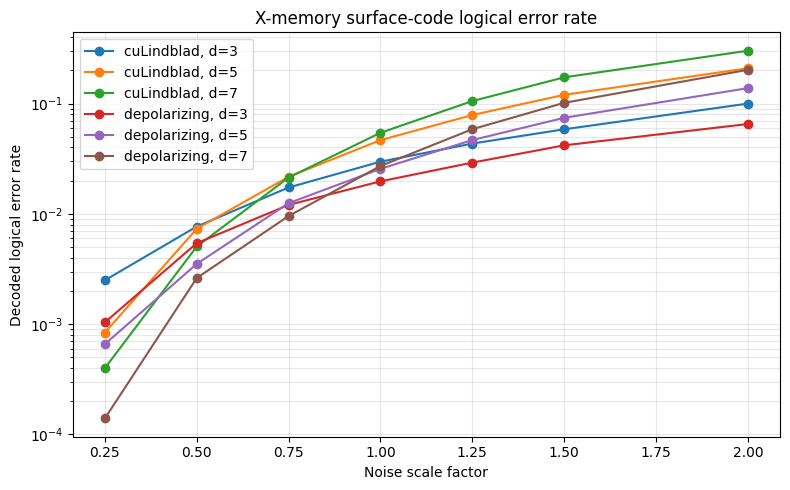

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(results)

print(df)

# Pivot table: rows = scale, columns = model/distance
table = df.pivot_table(
    index="scale",
    columns=["model", "distance"],
    values="pL",
)

print("\nLogical error-rate table:")
print(table)

# Plot X-memory decoded logical error rates
plt.figure(figsize=(8, 5))

for model_name in ["cuLindblad", "depolarizing"]:
    for d in sorted(df["distance"].unique()):
        sub = df[(df["model"] == model_name) & (df["distance"] == d)]
        plt.plot(
            sub["scale"],
            sub["pL"],
            marker="o",
            label=f"{model_name}, d={d}",
        )

plt.xlabel("Noise scale factor")
plt.ylabel("Decoded logical error rate")
plt.yscale("log")
plt.title("X-memory surface-code logical error rate")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()